In [179]:
import pandas as pd
import numpy as np
import os

os.makedirs("EDAs", exist_ok=True)


In [180]:
df = pd.read_csv("DatasetML.csv")


In [181]:
df.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,Meal,Country,MarketSegment,DistributionChannel,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,ReservedRoomType,AssignedRoomType,BookingChanges,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,7/3/2015
1,1,88,2015,July,27,1,0,4,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,7/1/2015
2,1,65,2015,July,27,1,0,4,1,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,4/30/2015
3,1,92,2015,July,27,1,2,4,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,6/23/2015
4,1,100,2015,July,27,2,0,2,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,4/2/2015


In [182]:
print(df.shape[0])

79330


In [183]:
df=df.drop_duplicates()

In [184]:
print(df.shape[0])

53428


In [185]:
no_adults = df["Adults"] == 0
print("Rows with 0 adults:", no_adults.sum())

df = df[~no_adults].copy()
print("Rows left:", len(df))

Rows with 0 adults: 373
Rows left: 53055


for the adr groups:
- each group label is a combination of its room type and party size (adults + children)
- within a room type, if a party size has fewer entries than 100 then it is merged with the nexty party size up (or size down for the very last one)
- if the entire room type has less than 100, then those will use the party size range alone instead

In [186]:
# Helpers for the outlier checks below

def iqr_flags(s):
    # true if value is an outlier according to the IQR rule
    Q1, Q3 = s.quantile([0.25, 0.75])
    IQR = Q3 - Q1
    return (s < Q1 - 1.5 * IQR) | (s > Q3 + 1.5 * IQR)


MIN_GROUP = 100   # minimum bookings needed for an ADR group to get its own IQR range

def adr_groups(df):

    #defining the adr groups i mentioned above
    party_size = (df["Adults"] + df["Children"].fillna(0)).clip(upper=4).replace(0, np.nan)
    room_type = df["ReservedRoomType"].str.strip()

    label = {}
    for room, sizes in party_size.groupby(room_type):
        counts = sizes.value_counts().sort_index()
        merged, current = [], []
        for size, n in counts.items():
            current.append(size)
            if counts[current].sum() >= MIN_GROUP:
                merged.append(current)
                current = []
        if current and merged:            # leftover small sizes join the previous group
            merged[-1] += current
        for group in merged:
            name = room + " " + "/".join("4+" if s == 4 else str(int(s)) for s in group)
            label.update({(room, s): name for s in group})

    group = pd.Series([label.get(k, np.nan) for k in zip(room_type, party_size)], index=df.index)
    return group, party_size
#the outputs are 2 pandas series with the same index as the original df and they contain which party size each entry will belong to
#same with the room type (contains merged rooms too)

In [187]:
# Outliers for the stay/lead-time columns use the usual IQR rule
# ADR is checked with the rules i write above

cols = ["LeadTime", "StaysInWeekendNights", "StaysInWeekNights"]

outlier = pd.Series(False, index=df.index)

for col in cols:
    is_out = iqr_flags(df[col])
    print(f"{col:30s} outliers: {is_out.sum():,}")
    outlier |= is_out

adr_group, party_size = adr_groups(df)
by_party = df["ADR"].groupby(party_size).transform(iqr_flags)      # fallback for tiny room types
is_out = df["ADR"].groupby(adr_group).transform(iqr_flags).fillna(by_party).fillna(False).astype(bool)

print(f"{'ADR (room type x party size)':30s} outliers: {is_out.sum():,}")
print(f"  rows using the party-size range (room type < {MIN_GROUP} bookings): "
      f"{(adr_group.isna() & party_size.notna()).sum():,}")
display(pd.DataFrame({
    "Bookings": adr_group.value_counts(),
    "Outliers": is_out.groupby(adr_group).sum(),
    "Outlier%": (is_out.groupby(adr_group).mean() * 100).round(1),
}).sort_index())
outlier |= is_out

before = len(df)                     # save the count BEFORE removing
df = df[~outlier].copy()             # remove outliers
after = len(df)

print(f"\nBefore: {before:,}  After: {after:,}  Removed: {before - after:,} ({(before - after) / before:.1%})")

LeadTime                       outliers: 1,679
StaysInWeekendNights           outliers: 73
StaysInWeekNights              outliers: 662
ADR (room type x party size)   outliers: 1,782
  rows using the party-size range (room type < 100 bookings): 13


,Bookings,Outliers,Outlier%
A 1,8793,691,7.9
A 2,26250,612,2.3
A 3/4+,2783,50,1.8
B 1/2,682,52,7.6
B 3/4+,106,1,0.9
D 1,1023,54,5.3
D 2,6164,94,1.5
D 3/4+,3557,106,3.0
E 1,262,18,6.9
E 2,552,19,3.4



Before: 53,055  After: 48,996  Removed: 4,059 (7.7%)


In [188]:
#remove spaces in stringed values
df = df.apply(lambda col: col.map(lambda x: x.strip() if isinstance(x, str) else x))

In [189]:
df = df.replace('NULL', np.nan)
df = df.replace('NA', np.nan)
df = df.replace('', np.nan)

In [190]:
print(df.isna().sum())

IsCanceled                         0
LeadTime                           0
ArrivalDateYear                    0
ArrivalDateMonth                   0
ArrivalDateWeekNumber              0
ArrivalDateDayOfMonth              0
StaysInWeekendNights               0
StaysInWeekNights                  0
Adults                             0
Children                           2
Babies                             0
Meal                               0
Country                            3
MarketSegment                      0
DistributionChannel                0
IsRepeatedGuest                    0
PreviousCancellations              0
PreviousBookingsNotCanceled        0
ReservedRoomType                   0
AssignedRoomType                   0
BookingChanges                     0
DepositType                        0
Agent                           4792
Company                        46544
DaysInWaitingList                  0
CustomerType                       0
ADR                                0
R

In [191]:
#Decision whether having a company matters in column values
group = df["Company"].notna().map({False: "No company", True: "Has company"})
cols = df.select_dtypes(include="number").columns

summary = df[cols].groupby(group).mean().T[["No company", "Has company"]]
summary["Difference"] = summary["Has company"] - summary["No company"]
print(summary.round(2))


Company                      No company  Has company  Difference
IsCanceled                         0.30         0.12       -0.18
LeadTime                          72.71        25.00      -47.71
ArrivalDateYear                 2016.26      2016.19       -0.06
ArrivalDateWeekNumber             26.41        26.77        0.37
ArrivalDateDayOfMonth             15.73        15.65       -0.08
StaysInWeekendNights               0.87         0.47       -0.40
StaysInWeekNights                  2.24         1.44       -0.79
Adults                             1.94         1.19       -0.75
Children                           0.13         0.01       -0.12
Babies                             0.01         0.00       -0.01
IsRepeatedGuest                    0.01         0.39        0.38
PreviousCancellations              0.02         0.25        0.23
PreviousBookingsNotCanceled        0.02         3.16        3.14
BookingChanges                     0.22         0.35        0.12
DaysInWaitingList        

In [192]:
summary = (
    df.groupby(df["Company"].notna())                      
      .agg(Bookings=("LeadTime", "size"),                 
           MedianLeadTime=("LeadTime", "median"),         
           MedianADR=("ADR", "median"))
      .rename(index={False: "No company", True: "Has company"})
)
summary.index.name = None
print(summary)



             Bookings  MedianLeadTime  MedianADR
No company      46544            53.0      108.0
Has company      2452             6.0       80.0


Having a company matters the most in MedianADR and Lead Time; therefore, it will be replaced with a HasCompany boolean instead of dropping it totally off

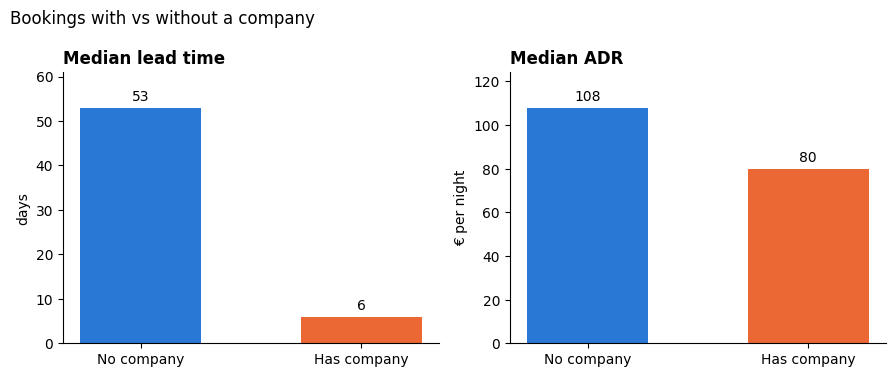

In [193]:
import matplotlib.pyplot as plt

colors = ["#2a78d6", "#eb6834"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))

for ax, col, title, unit in [
    (axes[0], "MedianLeadTime", "Median lead time", "days"),
    (axes[1], "MedianADR", "Median ADR", "€ per night"),
]:
    bars = ax.bar(summary.index, summary[col], color=colors, width=0.55)
    ax.bar_label(bars, fmt="%.0f", padding=3)          # value on top of each bar
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylabel(unit)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(0, summary[col].max() * 1.15)          # room for the labels

fig.suptitle("Bookings with vs without a company", x=0.01, ha="left")
plt.tight_layout()
plt.savefig("EDAs/company_leadtime_adr.png", dpi=150)       # for the report
plt.show()

In [194]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

missing_country = df[df["Country"].isna()]
print(len(missing_country))     # 24
print(missing_country)

3
       IsCanceled  LeadTime  ArrivalDateYear ArrivalDateMonth  \
4831            1       193             2015          October   
40770           0         4             2015         November   
61428           0         1             2016         November   

       ArrivalDateWeekNumber  ArrivalDateDayOfMonth  StaysInWeekendNights  \
4831                      42                     15                     0   
40770                     48                     23                     1   
61428                     47                     13                     2   

       StaysInWeekNights  Adults  Children  Babies Meal Country  \
4831                   3       2       0.0       0   BB     NaN   
40770                  2       1       0.0       0   BB     NaN   
61428                  2       2       0.0       0   BB     NaN   

       MarketSegment DistributionChannel  IsRepeatedGuest  \
4831   Offline TA/TO               TA/TO                0   
40770         Groups               TA

Dropped the rows with no countries (only 3 rows)

In [197]:
df["Children"] = df["Children"].fillna(0).astype(int)


df["HasCompany"] = df["Company"].notna().astype(int)
df = df.drop(columns=["Company"])

df["Agent"] = df["Agent"].fillna(0).astype(str)

In [198]:
df["ReservationStatusDate"] = pd.to_datetime(df["ReservationStatusDate"])

In [199]:
df.info()

<class 'pandas.DataFrame'>
Index: 48996 entries, 1 to 79328
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   IsCanceled                   48996 non-null  int64         
 1   LeadTime                     48996 non-null  int64         
 2   ArrivalDateYear              48996 non-null  int64         
 3   ArrivalDateMonth             48996 non-null  str           
 4   ArrivalDateWeekNumber        48996 non-null  int64         
 5   ArrivalDateDayOfMonth        48996 non-null  int64         
 6   StaysInWeekendNights         48996 non-null  int64         
 7   StaysInWeekNights            48996 non-null  int64         
 8   Adults                       48996 non-null  int64         
 9   Children                     48996 non-null  int64         
 10  Babies                       48996 non-null  int64         
 11  Meal                         48996 non-null  str         

In [200]:
df.to_csv("H2_cleaned.csv", index=False)